In [1]:
!pip install benchmarkfcns
from benchmarkfcns import sphere
import matplotlib.pyplot as plt
import torch
torch.set_default_dtype(torch.float64)

dim = 10

x = torch.randn(dim, 1)

def spheref(x):
  dim = x.shape[0]
  value = torch.sum(x**2)
  return value

worked = True

for i in range(1000):
  x = torch.randn(1,dim)
  tol = 1e-10
  my_val = spheref(x)
  bench_val = sphere(x)
  if abs(my_val-bench_val) > tol:
    worked = False

if worked:
  print("It worked!")
else:
  print("It no worky :(")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 171.8/171.8 kB 4.4 MB/s eta 0:00:00
It worked!


$$f(x) = \sum_i {x_i^2}$$

the differentiation of each value in the vector gives: $2x_i$. So the gradient is:

$$\nabla f(x) = 2x $$

In [2]:
def spheregrad(x):
  value = 2 * x
  return value
def sphere_AD(x):
  dim = x.shape[0]
  assert x.shape == (dim,1)
  # track input
  x.requires_grad = True
  y = spheref(x)
  dy = torch.autograd.grad(outputs=y, inputs= x , grad_outputs = torch.ones_like(y), create_graph= True)[0]

  # To save memory we want to untrack the grad
  x = x.detach_()
  y = y.detach_()
  dy = dy.detach_()
  return dy

We can use a similar approach to calculate the hessian. These values will only fall on the diagonal and they will all be the same since the function is only of order 2.

In [3]:
def spherehess(x):
  dim = x.shape[0]
  value = 2*torch.eye(dim)
  return value
def spherehess_AD(x):
  dim = x.shape[0]
  assert x.shape == (dim, 1)

  x.requires_grad = True
  dy = sphere_AD(x)
  hessian = torch.autograd.functional.hessian(spheref, x)
  return hessian.squeeze()

Testing:

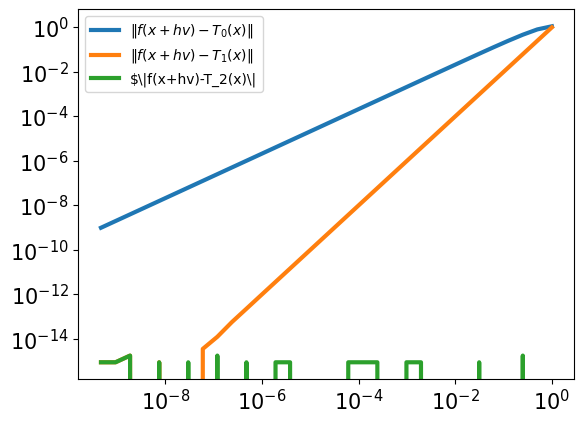

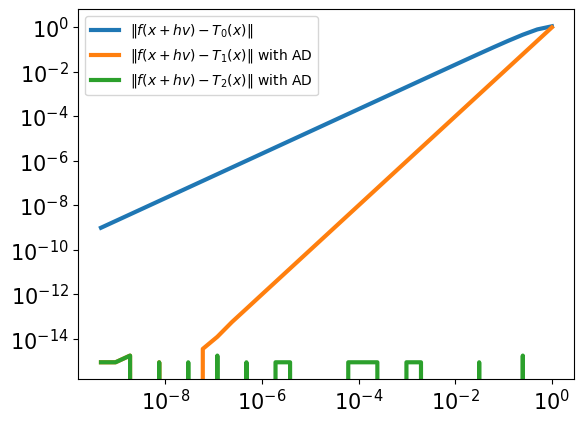

In [4]:
x = torch.randn(dim,1)
v = torch.randn_like(x)
v=v/torch.norm(v)

max_iters = 32
h = torch.zeros(max_iters)

err0 = torch.zeros(max_iters)
err1 = torch.zeros(max_iters)
err2 = torch.zeros(max_iters)
err3 = torch.zeros(max_iters)
err4 = torch.zeros(max_iters)

for i in range(max_iters):
  h[i] = 2**(-i)
  input = x+h[i]*v
  fv = spheref(input)
  T0 = spheref(x)
  T1 = T0 + h[i] * spheregrad(x).T @ v
  T2 = T1 + (1/2)*(h[i])**2 * v.T @ spherehess(x) @ v
  T1a = T0 + h[i] * sphere_AD(x).T @ v
  T2a = T1 + (1/2)*(h[i])**2 * v.T @ spherehess_AD(x) @ v

  err0[i]=torch.norm(fv-T0)
  err1[i]=torch.norm(fv-T1)
  err2[i]=torch.norm(fv-T2)
  err3[i]=torch.norm(fv-T1a)
  err4[i]=torch.norm(fv-T2a)

plt.loglog(h,err0, linewidth = 3)
plt.loglog(h, err1, linewidth=3)
plt.loglog(h, err2, linewidth=3)

plt.legend(['$\|f(x+hv)-T_0(x)\|$','$\|f(x+hv)-T_1(x)\|$','$\|f(x+hv)-T_2(x)\|'])
plt.xticks(fontsize = 15)
plt.yticks(fontsize = 15)
plt.show()

plt.loglog(h,err0, linewidth = 3)
plt.loglog(h, err3, linewidth=3)
plt.loglog(h, err4, linewidth=3)
plt.legend(['$\|f(x+hv)-T_0(x)\|$','$\|f(x+hv)-T_1(x)\|$ with AD','$\|f(x+hv)-T_2(x)\|$ with AD'])
plt.xticks(fontsize = 15)
plt.yticks(fontsize = 15)
plt.show()